# Task 6 (Phương án B) — Đánh giá định lượng tác động của sửa lỗi `capacity_train_only` (Đủ 5 Seed DQN & 5 Seed A2C_mod)

**Mục tiêu:**
- Cung cấp bằng chứng định lượng đầy đủ cho **§2.1.3 & Table 3** khi thay `capacity_full` (mean = `20.33`) bằng `capacity_train_only` (mean = `25.79`).
- Đánh giá ghép cặp (504 bước test × 4 kịch bản `ALL / EASY / MEDIUM / HARD`) đối xứng hoàn toàn giữa 2 môi trường cho:
  - **Base-Stock (`k = 1.0`, val-selected)**
  - **DQN — đủ 5 seed (`42, 123, 256, 512, 1024`)** từ `dqn/checkpoints_dqn_comparison{seed}` (tự nạp checkpoint mới nhất: `ckpt-50`, riêng seed `512` là `ckpt-43`)
  - **`A2C_mod` — đủ 5 seed (`42, 123, 256, 512, 1024`)** từ `Feedback 23-11/` (`ckpt-53` cho seed `42`, `ckpt-60` cho các seed còn lại)
- Báo cáo $\Delta = \text{Train-only} - \text{Full}$ cho cả **6 metric** (*Total Reward, Service Level, Holding, Waste, Ordering/Balance, Stockout*) kèm **95% Bootstrap CI, Paired t-test, Wilcoxon, Hedges' $g$, và TOST ($\pm 0.02$)** theo cả 504 bước test và theo 5 seed.


In [5]:
import os, sys, json, time, random, warnings, pathlib
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy import stats

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CWD = pathlib.Path.cwd()
REPO_ROOT = CWD
for cand in [CWD, CWD.parent, CWD.parent.parent, pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management")]:
    if (cand / "data" / "test.tfrecords").exists():
        REPO_ROOT = cand
        break

DATA_DIR = REPO_ROOT / "data"
TASK6_DIR = REPO_ROOT / "Feedback 23-11" / "task6"
TASK6_DATA_DIR = TASK6_DIR / "data"
OUTPUT_DIR = TASK6_DIR / "output"
FIGS_DIR = OUTPUT_DIR / "figs"
for d in [TASK6_DATA_DIR, OUTPUT_DIR, FIGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

AUDIT_CAP_CSV = REPO_ROOT / "Feedback 7-9" / "task13-9" / "task2" / "output" / "output_audit_34_capacity_diff.csv"
assert AUDIT_CAP_CSV.exists(), f"Missing {AUDIT_CAP_CSV}"

NUM_PRODUCTS = 220
NUM_ACTIONS = 14
ZERO_INV = 1e-5
SEEDS_5 = ["42", "123", "256", "512", "1024"]
ACTION_LEVELS = np.array(
    [0.0, 0.005, 0.01, 0.0125, 0.015, 0.0175, 0.02, 0.03, 0.04, 0.08, 0.12, 0.2, 0.5, 1.0],
    dtype=np.float32,
)

def sales_parser(s):
    return tf.io.parse_single_example(s, {"sales": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)})
def capacity_parser(s):
    return tf.io.parse_single_example(s, {"capacity": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)})
def stock_parser(s):
    return tf.io.parse_single_example(s, {"stock": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)})

cap_full = next(iter(tf.data.TFRecordDataset(str(DATA_DIR / "capacity.tfrecords")).map(capacity_parser)))["capacity"].numpy().astype(np.float32)
x_init = next(iter(tf.data.TFRecordDataset(str(DATA_DIR / "stock.tfrecords")).map(stock_parser)))["stock"].numpy().astype(np.float32)
train_sales_raw = np.array([r["sales"].numpy() for r in tf.data.TFRecordDataset(str(DATA_DIR / "train.tfrecords")).map(sales_parser)], dtype=np.float32)
test_sales_raw = np.array([r["sales"].numpy() for r in tf.data.TFRecordDataset(str(DATA_DIR / "test.tfrecords")).map(sales_parser)], dtype=np.float32)

df_cap = pd.read_csv(AUDIT_CAP_CSV).sort_values("product_id")
cap_full_csv = df_cap["capacity_full"].to_numpy(dtype=np.float32)
cap_train_only = df_cap["capacity_train_only"].to_numpy(dtype=np.float32)
assert len(cap_train_only) == NUM_PRODUCTS
assert np.max(np.abs(cap_full - cap_full_csv)) < 1e-3, "Capacity alignment mismatch!"

cap_tfrec_path = TASK6_DATA_DIR / "capacity_train_only.tfrecords"
with tf.io.TFRecordWriter(str(cap_tfrec_path)) as writer:
    ex = tf.train.Example(features=tf.train.Features(feature={
        "capacity": tf.train.Feature(float_list=tf.train.FloatList(value=cap_train_only.tolist()))
    }))
    writer.write(ex.SerializeToString())

print(f"TensorFlow: {tf.__version__}")
print(f"Train sales: {train_sales_raw.shape} | Test sales: {test_sales_raw.shape}")
print(f"capacity_full mean      = {cap_full.mean():.4f}")
print(f"capacity_train_only mean= {cap_train_only.mean():.4f} (mean diff% = {df_cap['diff_pct'].mean():.2f}%)")
print(f"OK: Exported {cap_tfrec_path}")


TensorFlow: 2.20.0
Train sales: (1000, 220) | Test sales: (504, 220)
capacity_full mean      = 20.3273
capacity_train_only mean= 25.7864 (mean diff% = 26.29%)
OK: Exported c:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\task6\data\capacity_train_only.tfrecords


## 1. Load All 10 Real Checkpoints (5 Seeds `DQN` + 5 Seeds `A2C_mod`)


In [6]:
class Dense(tf.Module):
    def __init__(self, input_dim, output_size, activation=None, stddev=1.0):
        super().__init__()
        self.w = tf.Variable(tf.random.truncated_normal([input_dim, output_size], stddev=stddev), name="w")
        self.b = tf.Variable(tf.zeros([output_size]), name="b")
        self.activation = activation
    def __call__(self, x):
        y = tf.matmul(x, self.w) + self.b
        return self.activation(y) if self.activation else y

class Actor(tf.Module):
    def __init__(self, num_features=3, num_actions=14, hidden_size=32, activation=tf.nn.relu):
        super().__init__()
        self.layer1 = Dense(num_features, hidden_size)
        self.layer2 = Dense(hidden_size, hidden_size)
        self.layer3 = Dense(hidden_size, hidden_size)
        self.layer4 = Dense(hidden_size, num_actions)
        self.activation = activation
    def __call__(self, state):
        x = self.activation(self.layer1(state))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        return tf.nn.softmax(self.layer4(x), axis=-1)

class MultiProductQNetwork(tf.keras.Model):
    def __init__(self, num_features=660, num_products=220, num_actions=14, hidden_size=128, dropout_prob=0.1, use_group_norm=True):
        super().__init__()
        self.num_products = num_products
        self.num_actions = num_actions
        self.features_per_prod = num_features // num_products
        self.dense1 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.dense2 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.dense3 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.out = tf.keras.layers.Dense(num_actions, activation=None)
        self._use_gn = use_group_norm
        if use_group_norm:
            self.gn1 = tf.keras.layers.GroupNormalization(groups=1)
            self.gn2 = tf.keras.layers.GroupNormalization(groups=1)
            self.gn3 = tf.keras.layers.GroupNormalization(groups=1)
        self.drop1 = tf.keras.layers.Dropout(dropout_prob)
        self.drop2 = tf.keras.layers.Dropout(dropout_prob)
        self.drop3 = tf.keras.layers.Dropout(dropout_prob)
    def call(self, state, training=False):
        B = tf.shape(state)[0]
        P, F = self.num_products, self.features_per_prod
        s3d = tf.transpose(tf.reshape(state, [B, F, P]), [0, 2, 1])
        x = tf.reshape(s3d, [B * P, F])
        x = self.dense1(x)
        if self._use_gn: x = self.gn1(x, training=training)
        x = self.drop1(tf.nn.relu(x), training=training)
        x = self.dense2(x)
        if self._use_gn: x = self.gn2(x, training=training)
        x = self.drop2(tf.nn.relu(x), training=training)
        x = self.dense3(x)
        if self._use_gn: x = self.gn3(x, training=training)
        x = self.drop3(tf.nn.relu(x), training=training)
        return tf.reshape(self.out(x), [B, P, self.num_actions])

def load_dqn_checkpoint(ckpt_dir):
    latest = tf.train.latest_checkpoint(str(ckpt_dir))
    assert latest is not None, f"No DQN checkpoint in {ckpt_dir}"
    avail_shapes = dict(tf.train.list_variables(latest))
    avail = set(avail_shapes.keys())
    prefix = "q_network" if any(n.startswith("q_network/") for n in avail) else "target_network"
    k_name = "kernel" if f"{prefix}/dense1/kernel/.ATTRIBUTES/VARIABLE_VALUE" in avail else "_kernel"
    hidden_size = int(avail_shapes[f"{prefix}/dense1/{k_name}/.ATTRIBUTES/VARIABLE_VALUE"][1])

    net = MultiProductQNetwork(hidden_size=hidden_size)
    _ = net(tf.zeros([1, 660], dtype=tf.float32), training=False)
    w_before = float(tf.norm(net.dense1.kernel))

    mapping = [
        (net.dense1.kernel, f"{prefix}/dense1/{k_name}"), (net.dense1.bias, f"{prefix}/dense1/bias"),
        (net.dense2.kernel, f"{prefix}/dense2/{k_name}"), (net.dense2.bias, f"{prefix}/dense2/bias"),
        (net.dense3.kernel, f"{prefix}/dense3/{k_name}"), (net.dense3.bias, f"{prefix}/dense3/bias"),
        (net.gn1.gamma,     f"{prefix}/gn1/gamma"),       (net.gn1.beta,    f"{prefix}/gn1/beta"),
        (net.gn2.gamma,     f"{prefix}/gn2/gamma"),       (net.gn2.beta,    f"{prefix}/gn2/beta"),
        (net.gn3.gamma,     f"{prefix}/gn3/gamma"),       (net.gn3.beta,    f"{prefix}/gn3/beta"),
        (net.out.kernel,    f"{prefix}/out/{k_name}"),    (net.out.bias,    f"{prefix}/out/bias"),
    ]
    for var, key in mapping:
        full_key = f"{key}/.ATTRIBUTES/VARIABLE_VALUE"
        assert full_key in avail, f"Missing {full_key} in {latest}"
        var.assign(tf.train.load_variable(latest, full_key))

    w_after = float(tf.norm(net.dense1.kernel))
    assert abs(w_after - w_before) > 1e-5, f"DQN weights unchanged for {latest}!"
    return net, latest, w_after, hidden_size

# 1) Load 5 seeds of DQN using explicit absolute paths
DQN_DIRS = {
    "42":   r"C:\GitHub\Q-learning-for-Inventory-Management\dqn\checkpoints_dqn_comparison42",
    "123":  r"C:\GitHub\Q-learning-for-Inventory-Management\dqn\checkpoints_dqn_comparison123",
    "256":  r"C:\GitHub\Q-learning-for-Inventory-Management\dqn\checkpoints_dqn_comparison256",
    "512":  r"C:\GitHub\Q-learning-for-Inventory-Management\dqn\checkpoints_dqn_comparison512",
    "1024": r"C:\GitHub\Q-learning-for-Inventory-Management\dqn\checkpoints_dqn_comparison1024",
}
dqn_nets = {}
dqn_ckpt_info = {}
for s in SEEDS_5:
    net, latest, wnorm, h_sz = load_dqn_checkpoint(DQN_DIRS[s])
    dqn_nets[s] = net
    dqn_ckpt_info[s] = f"{pathlib.Path(latest).name} (hidden={h_sz})"
    print(f"OK: DQN     [seed {s:4s}] restored -> {pathlib.Path(latest).name} (hidden={h_sz}, dense1 norm={wnorm:.4f})")

# 2) Load 5 seeds of A2C_mod using explicit absolute paths
A2C_CKPTS = {
    "42":   pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\checkpoints_a2c_42\ckpt-53"),
    "123":  pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\A2C_mod_123\checkpoints\ckpt-60"),
    "256":  pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\A2C_mod_256\checkpoints\ckpt-60"),
    "512":  pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\checkpoints_a2c_512\ckpt-60"),
    "1024": pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\checkpoints_a2c_1024\ckpt-60"),
}
a2c_actors = {}
for s, ckpt_path in A2C_CKPTS.items():
    assert pathlib.Path(str(ckpt_path) + ".index").exists(), f"Missing A2C checkpoint: {ckpt_path}"
    act = Actor()
    _ = act(tf.zeros([1, 3], dtype=tf.float32))
    w0 = float(tf.norm(act.layer1.w))
    tf.train.Checkpoint(actor=act).restore(str(ckpt_path)).expect_partial()
    w1 = float(tf.norm(act.layer1.w))
    assert abs(w1 - w0) > 1e-5, f"A2C {s} weights unchanged!"
    a2c_actors[s] = act
    print(f"OK: A2C_mod [seed {s:4s}] restored -> {ckpt_path.name} (layer1 norm={w1:.4f})")


OK: DQN     [seed 42  ] restored -> ckpt-50 (hidden=128, dense1 norm=23.9807)
OK: DQN     [seed 123 ] restored -> ckpt-50 (hidden=128, dense1 norm=25.9539)
OK: DQN     [seed 256 ] restored -> ckpt-50 (hidden=128, dense1 norm=25.1191)
OK: DQN     [seed 512 ] restored -> ckpt-43 (hidden=32, dense1 norm=13.8505)
OK: DQN     [seed 1024] restored -> ckpt-50 (hidden=128, dense1 norm=25.5367)
OK: A2C_mod [seed 42  ] restored -> ckpt-53 (layer1 norm=8.3177)
OK: A2C_mod [seed 123 ] restored -> ckpt-60 (layer1 norm=8.6017)
OK: A2C_mod [seed 256 ] restored -> ckpt-60 (layer1 norm=9.0679)
OK: A2C_mod [seed 512 ] restored -> ckpt-60 (layer1 norm=7.6431)
OK: A2C_mod [seed 1024] restored -> ckpt-60 (layer1 norm=9.9056)


## 2. Paired Evaluation on `capacity_full` vs. `capacity_train_only` (504 Test Steps × 4 Scenarios)


In [7]:
SCENARIOS = {
    "ALL":    {"x_scale": 1.0, "sales_scale": 1.0, "waste_rate": 0.025},
    "EASY":   {"x_scale": 0.3, "sales_scale": 0.2, "waste_rate": 0.010},
    "MEDIUM": {"x_scale": 0.6, "sales_scale": 0.5, "waste_rate": 0.050},
    "HARD":   {"x_scale": 0.9, "sales_scale": 0.8, "waste_rate": 0.150},
}
METRICS = ["total_reward", "service_level", "holding_cost", "waste_cost", "ordering_cost", "stockout_rate"]

def fit_base_stock_target(capacity_vec, k=1.0, fit_steps=800):
    train_norm = train_sales_raw[:fit_steps] / capacity_vec
    mu = train_norm.mean(axis=0)
    sd = train_norm.std(axis=0)
    return np.clip(mu + k * sd, 0.0, 1.0).astype(np.float32)

def rollout_policy(policy_fn, capacity_vec, sc_cfg):
    sales_norm = (test_sales_raw / capacity_vec) * sc_cfg["sales_scale"]
    x = np.clip(x_init * sc_cfg["x_scale"], 0.0, 1.0).astype(np.float32)
    T = len(sales_norm)
    out = {m: np.zeros(T, dtype=np.float64) for m in METRICS}

    for t in range(T):
        sales_t = sales_norm[t].astype(np.float32)
        q_t = (x * sc_cfg["waste_rate"]).astype(np.float32)
        u = policy_fn(x, sales_t, q_t)

        overstock = np.maximum(0.0, (x + u) - 1.0)
        x_u = np.minimum(1.0, x + u)
        z = (x < ZERO_INV).astype(np.float32)
        quan = float(np.quantile(x, 0.95) - np.quantile(x, 0.05))
        r = 1.0 - z - overstock - q_t - quan

        out["total_reward"][t] = float(r.mean())
        out["service_level"][t] = float((1.0 - z).mean())
        out["holding_cost"][t] = float(overstock.mean())
        out["waste_cost"][t] = float(q_t.mean())
        out["ordering_cost"][t] = quan
        out["stockout_rate"][t] = float(z.mean())

        x = np.maximum(0.0, x_u - sales_t).astype(np.float32)
    return out

def make_bs_fn(S_target):
    return lambda x, sales_t, q_t: np.maximum(0.0, S_target - x).astype(np.float32)

def make_dqn_fn(net):
    def fn(x, sales_t, q_t):
        s660 = np.concatenate([x, sales_t, q_t], axis=0)[None, :]
        q = net(tf.constant(s660, dtype=tf.float32), training=False).numpy()[0]
        return ACTION_LEVELS[np.argmax(q, axis=-1)]
    return fn

def make_a2c_fn(actor_model):
    def fn(x, sales_t, q_t):
        s_pp = np.stack([x, sales_t, q_t], axis=1)
        probs = actor_model(tf.constant(s_pp, dtype=tf.float32)).numpy()
        return ACTION_LEVELS[np.argmax(probs, axis=-1)]
    return fn

t0 = time.time()
raw_eval = {}

bs_targets = {
    "full": fit_base_stock_target(cap_full, k=1.0),
    "train_only": fit_base_stock_target(cap_train_only, k=1.0),
}

for sc_name, sc_cfg in SCENARIOS.items():
    for cap_name, cap_vec in [("full", cap_full), ("train_only", cap_train_only)]:
        raw_eval[("Base-Stock", sc_name, cap_name)] = rollout_policy(make_bs_fn(bs_targets[cap_name]), cap_vec, sc_cfg)
        for s in SEEDS_5:
            raw_eval[(f"DQN_{s}", sc_name, cap_name)] = rollout_policy(make_dqn_fn(dqn_nets[s]), cap_vec, sc_cfg)
            raw_eval[(f"A2C_mod_{s}", sc_name, cap_name)] = rollout_policy(make_a2c_fn(a2c_actors[s]), cap_vec, sc_cfg)
    print(f"OK: Finished scenario {sc_name} ({time.time() - t0:.1f}s)")


OK: Finished scenario ALL (57.0s)
OK: Finished scenario EASY (111.8s)
OK: Finished scenario MEDIUM (166.6s)
OK: Finished scenario HARD (221.7s)


## 3. Statistical Tests ($\Delta$, 95% Bootstrap CI, Paired t-test, Wilcoxon, Hedges' $g$, TOST $\pm 0.02$)


In [8]:
def paired_stats(arr_full, arr_train, tost_bound=0.02, n_boot=2000, seed=SEED):
    diff = arr_train - arr_full
    n = len(diff)
    mean_full = float(np.mean(arr_full))
    mean_train = float(np.mean(arr_train))
    delta = float(np.mean(diff))
    sd_diff = float(np.std(diff, ddof=1))

    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    boot_means = diff[idx].mean(axis=1)
    ci_lo, ci_hi = float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5))

    if sd_diff < 1e-12:
        t_p, w_p, g_val, tost_p = 1.0, 1.0, 0.0, (0.0 if abs(delta) < tost_bound else 1.0)
    else:
        _, t_p = stats.ttest_rel(arr_train, arr_full)
        try:
            _, w_p = stats.wilcoxon(diff, zero_method="wilcox")
        except Exception:
            w_p = 1.0
        J = 1.0 - 3.0 / (4.0 * n - 5.0) if n > 2 else 1.0
        g_val = float((delta / sd_diff) * J)
        se = sd_diff / np.sqrt(n)
        p_low = 1.0 - stats.t.cdf((delta - (-tost_bound)) / se, df=n - 1)
        p_high = 1.0 - stats.t.cdf((tost_bound - delta) / se, df=n - 1)
        tost_p = float(max(p_low, p_high))

    return {
        "full_mean": mean_full, "train_only_mean": mean_train,
        "delta": delta, "delta_sd": sd_diff,
        "ci95_lo": ci_lo, "ci95_hi": ci_hi,
        "ttest_p": float(t_p), "wilcoxon_p": float(w_p),
        "hedges_g": float(g_val), "tost_p_002": float(tost_p), "equiv_002": bool(tost_p < 0.05),
    }

# 1) Per-step paired tests (n=504 test steps) for Base-Stock, DQN (5-seed mean), A2C_mod (5-seed mean)
step_rows = []
for sc_name in SCENARIOS:
    dqn5_full = {m: np.mean([raw_eval[(f"DQN_{s}", sc_name, "full")][m] for s in SEEDS_5], axis=0) for m in METRICS}
    dqn5_tr   = {m: np.mean([raw_eval[(f"DQN_{s}", sc_name, "train_only")][m] for s in SEEDS_5], axis=0) for m in METRICS}
    a2c5_full = {m: np.mean([raw_eval[(f"A2C_mod_{s}", sc_name, "full")][m] for s in SEEDS_5], axis=0) for m in METRICS}
    a2c5_tr   = {m: np.mean([raw_eval[(f"A2C_mod_{s}", sc_name, "train_only")][m] for s in SEEDS_5], axis=0) for m in METRICS}

    for ag_label, d_full, d_tr in [
        ("Base-Stock (k=1.0)", raw_eval[("Base-Stock", sc_name, "full")], raw_eval[("Base-Stock", sc_name, "train_only")]),
        ("DQN (5-seed mean)", dqn5_full, dqn5_tr),
        ("A2C_mod (5-seed mean)", a2c5_full, a2c5_tr),
    ]:
        for m in METRICS:
            step_rows.append({"scenario": sc_name, "agent": ag_label, "metric": m, **paired_stats(d_full[m], d_tr[m], tost_bound=0.02)})

df_step = pd.DataFrame(step_rows)
df_step.to_csv(OUTPUT_DIR / "task6_paired_step_tests.csv", index=False)

# 2) Across-seed paired tests (n=5 seeds) for BOTH DQN and A2C_mod
seed_rows = []
for ag_prefix in ["DQN", "A2C_mod"]:
    for sc_name in SCENARIOS:
        for m in METRICS:
            vals_full = np.array([raw_eval[(f"{ag_prefix}_{s}", sc_name, "full")][m].mean() for s in SEEDS_5])
            vals_tr   = np.array([raw_eval[(f"{ag_prefix}_{s}", sc_name, "train_only")][m].mean() for s in SEEDS_5])
            seed_rows.append({
                "agent": ag_prefix, "scenario": sc_name, "metric": m,
                "full_seed_mean": float(vals_full.mean()), "full_seed_sd": float(vals_full.std(ddof=1)),
                "train_seed_mean": float(vals_tr.mean()), "train_seed_sd": float(vals_tr.std(ddof=1)),
                **paired_stats(vals_full, vals_tr, tost_bound=0.02),
            })

df_seed = pd.DataFrame(seed_rows)
df_seed.to_csv(OUTPUT_DIR / "task6_5seed_paired_summary.csv", index=False)

print("=== ALL Scenario: Capacity Full vs. Train-Only (n=504 test steps) ===")
cols = ["agent", "metric", "full_mean", "train_only_mean", "delta", "ci95_lo", "ci95_hi", "wilcoxon_p", "tost_p_002", "equiv_002"]
print(df_step[df_step["scenario"] == "ALL"][cols].to_string(index=False))

print("\n=== Total Reward Delta Across All 4 Scenarios ===")
print(df_step[df_step["metric"] == "total_reward"][["scenario", "agent", "full_mean", "train_only_mean", "delta", "ci95_lo", "ci95_hi", "tost_p_002", "equiv_002"]].to_string(index=False))

print("\n=== Across-Seed Paired Summary (ALL, n=5 seeds) ===")
print(df_seed[df_seed["scenario"] == "ALL"][["agent", "metric", "full_seed_mean", "full_seed_sd", "train_seed_mean", "train_seed_sd", "delta", "ttest_p", "tost_p_002", "equiv_002"]].to_string(index=False))


=== ALL Scenario: Capacity Full vs. Train-Only (n=504 test steps) ===
                agent        metric  full_mean  train_only_mean     delta   ci95_lo   ci95_hi   wilcoxon_p  tost_p_002  equiv_002
   Base-Stock (k=1.0)  total_reward   0.755075         0.806312  0.051237  0.048939  0.053513 2.523799e-72         1.0      False
   Base-Stock (k=1.0) service_level   0.982278         0.982413  0.000135  0.000063  0.000225 2.407884e-03         0.0       True
   Base-Stock (k=1.0)  holding_cost   0.000000         0.000000  0.000000  0.000000  0.000000 1.000000e+00         0.0       True
   Base-Stock (k=1.0)    waste_cost   0.005689         0.004571 -0.001118 -0.001139 -0.001094 6.639421e-84         0.0       True
   Base-Stock (k=1.0) ordering_cost   0.221515         0.171531 -0.049984 -0.052268 -0.047660 3.343829e-71         1.0      False
   Base-Stock (k=1.0) stockout_rate   0.017722         0.017587 -0.000135 -0.000225 -0.000063 3.176351e-03         0.0       True
    DQN (5-seed mean

## 4. Visualization & Export `task6_summary.json`


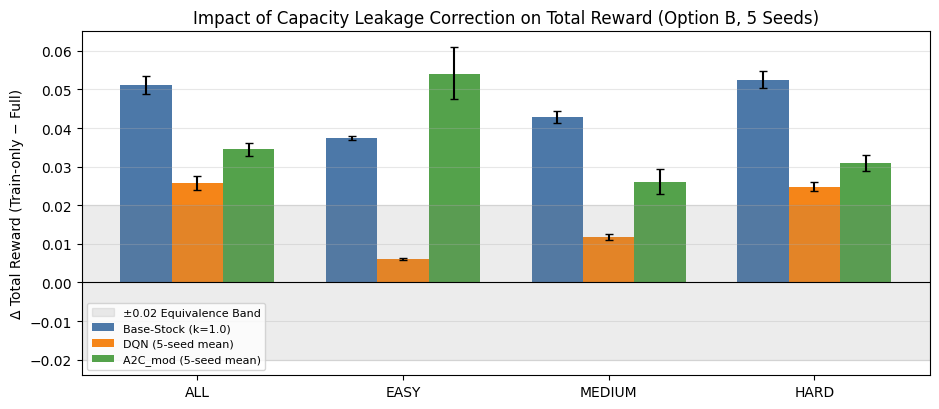

OK: Saved all Task 6 outputs to c:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\task6\output
 - task6_5seed_paired_summary.csv
 - task6_paired_step_tests.csv
 - task6_summary.json


In [9]:
sub = df_step[df_step["metric"] == "total_reward"]
agents_plot = ["Base-Stock (k=1.0)", "DQN (5-seed mean)", "A2C_mod (5-seed mean)"]
sc_list = ["ALL", "EASY", "MEDIUM", "HARD"]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x_pos = np.arange(len(sc_list))
width = 0.25
colors = ["#4C78A8", "#F58518", "#54A24B"]

for idx, ag in enumerate(agents_plot):
    d_ag = sub[sub["agent"] == ag].set_index("scenario").loc[sc_list]
    deltas = d_ag["delta"].to_numpy()
    err_lo = deltas - d_ag["ci95_lo"].to_numpy()
    err_hi = d_ag["ci95_hi"].to_numpy() - deltas
    ax.bar(x_pos + (idx - 1) * width, deltas, width, yerr=[err_lo, err_hi], capsize=3, label=ag, color=colors[idx])

ax.axhline(0.0, color="black", linewidth=0.8)
ax.axhspan(-0.02, 0.02, color="gray", alpha=0.15, label="±0.02 Equivalence Band")
ax.set_xticks(x_pos)
ax.set_xticklabels(sc_list)
ax.set_ylabel("Δ Total Reward (Train-only − Full)")
ax.set_title("Impact of Capacity Leakage Correction on Total Reward (Option B, 5 Seeds)")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGS_DIR / "task6_capacity_delta_reward.png", dpi=200, bbox_inches="tight")
plt.show()

summary = {
    "dqn_ckpts": dqn_ckpt_info,
    "a2c_ckpts": {s: p.name for s, p in A2C_CKPTS.items()},
    "capacity_stats": {
        "full_mean": float(cap_full.mean()),
        "train_only_mean": float(cap_train_only.mean()),
        "mean_diff_pct": float(df_cap["diff_pct"].mean()),
        "max_diff_pct": float(df_cap["diff_pct"].max()),
        "n_gt_10pct": int((df_cap["diff_pct"] > 10.0).sum()),
    },
    "all_scenario_step_tests": df_step[df_step["scenario"] == "ALL"].to_dict(orient="records"),
    "reward_by_scenario": df_step[df_step["metric"] == "total_reward"].to_dict(orient="records"),
    "five_seed_summary_all": df_seed[df_seed["scenario"] == "ALL"].to_dict(orient="records"),
}
with open(OUTPUT_DIR / "task6_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"OK: Saved all Task 6 outputs to {OUTPUT_DIR}")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(" -", p.name)
